# Submission 2: Pretrained CNNs, with and without fine-tuning
**Dataset:** SCAB benchmark (original images, Scabies vs Healthy)
**Models:** ResNet50, VGG16, EfficientNetB0
**Modes:** Feature extraction (backbone frozen) and Fine-tuning (backbone unfrozen)
**Outputs per run:** accuracy curve, loss curve, classification report, test confusion matrix

Before running: Runtime, Change runtime type, T4 GPU.

## 0. Colab setup
Connects Google Drive and unzips the images into Colab's fast local disk.
Needs `SCAB_original.zip` and `SCAB_metadata_CSV.csv` in the top level of My Drive.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

!rm -rf /content/data
!mkdir -p /content/data
!unzip -q "/content/drive/MyDrive/SCAB_original.zip" -d /content/data
!ls /content/data

Mounted at /content/drive
SCAB_original


## 1. Imports

In [2]:
import os, time, random
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from tensorflow.keras import layers, models, callbacks
from tensorflow.keras.applications import ResNet50, VGG16, EfficientNetB0
from tensorflow.keras.applications import resnet50, vgg16, efficientnet

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
print(tf.__version__)
print(tf.config.list_physical_devices('GPU'))

2.21.0
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Settings

In [3]:
DATA_ROOT = '/content/data'
CSV_PATH = '/content/drive/MyDrive/SCAB_metadata_CSV.csv'

IMG = 224
BATCH = 32
EPOCHS = 30
CLASS_NAMES = ['Healthy', 'Scabies']

## 3. Match the CSV to the image files
- The code scans the unzipped folder and finds every image by its file name, so it works whatever the folder layout is.
- The patient ID is the `PAT_xxx` part of the image name. Each patient has several photos, so it is used for the split in the next step.
- The table at the end must show Healthy images only in the healthy folder and Scabies images only in the Scabies folder.

In [4]:
index = {}
for root, dirs, files in os.walk(DATA_ROOT):
    if '__MACOSX' in root:
        continue
    for f in files:
        if f.lower().endswith(('.jpg', '.jpeg', '.png')) and not f.startswith('._'):
            index[f] = os.path.join(root, f)
print('Images found in zip:', len(index))

df = pd.read_csv(CSV_PATH)
df = df.dropna(subset=['Image_id'])
df = df[['Image_id', 'Class Label']].copy()
df.columns = ['image', 'class_name']

df['patient'] = df['image'].str.extract(r'^(PAT_\d+)')[0]
df['label'] = (df['class_name'] == 'Scabies').astype(int)
df['path'] = df['image'].map(index)
df['folder'] = df['path'].map(lambda p: os.path.basename(os.path.dirname(p)) if isinstance(p, str) else None)

print('Total images in CSV:', len(df))
print('Missing files:', df['path'].isna().sum())
assert df['path'].notna().all(), 'Some CSV images were not found in the unzipped folder'
pd.crosstab(df['folder'], df['class_name'])

Images found in zip: 606
Total images in CSV: 606
Missing files: 0


class_name,Healthy,Scabies
folder,,
Scabies,0,406
healthy,200,0


## 4. Train / validation / test split (by patient)
Photos of the same patient look very similar. If they land in both train and test, the test score becomes unfairly high (data leakage).
So we split **patients**, not images: 70% train, 15% validation, 15% test, stratified by class.

In [5]:
patients = df.groupby('patient', as_index=False)['label'].first()

train_p, temp_p = train_test_split(patients, test_size=0.30, stratify=patients['label'], random_state=SEED)
val_p, test_p = train_test_split(temp_p, test_size=0.50, stratify=temp_p['label'], random_state=SEED)

train_df = df[df['patient'].isin(train_p['patient'])]
val_df = df[df['patient'].isin(val_p['patient'])]
test_df = df[df['patient'].isin(test_p['patient'])]

summary = pd.DataFrame({
    'Split': ['Train', 'Validation', 'Test'],
    'Patients': [len(train_p), len(val_p), len(test_p)],
    'Images': [len(train_df), len(val_df), len(test_df)],
    'Healthy': [(d['label'] == 0).sum() for d in (train_df, val_df, test_df)],
    'Scabies': [(d['label'] == 1).sum() for d in (train_df, val_df, test_df)],
})
print('Patient overlap train/test:', len(set(train_p['patient']) & set(test_p['patient'])))
summary

Patient overlap train/test: 0


,Split,Patients,Images,Healthy,Scabies
0,Train,118,423,140,283
1,Validation,25,92,27,65
2,Test,26,91,33,58


## 5. Build the data pipelines
Images are resized to 224x224. Augmentation is applied later inside the model, and only during training.

In [6]:
def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, (IMG, IMG))
    return img, tf.cast(label, tf.float32)

def make_ds(d, train=False):
    ds = tf.data.Dataset.from_tensor_slices((d['path'].values, d['label'].values))
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE).cache()
    if train:
        ds = ds.shuffle(len(d), seed=SEED)
    return ds.batch(BATCH).prefetch(tf.data.AUTOTUNE)

train_ds = make_ds(train_df, train=True)
val_ds = make_ds(val_df)
test_ds = make_ds(test_df)

y_train = train_df['label'].values
y_test = test_df['label'].values

weights = len(y_train) / (2 * np.bincount(y_train))
class_weight = {0: weights[0], 1: weights[1]}
print('Class weights:', class_weight)

Class weights: {0: np.float64(1.5107142857142857), 1: np.float64(0.7473498233215548)}


## 6. Model builder
Every model has the same structure:
**Augmentation -> pretrained backbone -> global average pooling -> dropout -> 1 sigmoid output**

- `fine_tune=False`: backbone frozen, only the new output layer learns (learning rate 1e-3).
- `fine_tune=True`: backbone unfrozen and trained slowly (learning rate 1e-5).
- `last_layers`: unfreeze only the last N backbone layers (used later to fix overfitting).
- `dropout`: raise it to fight overfitting.

In [7]:
augment = tf.keras.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
])

ARCHS = {
    'ResNet50': (ResNet50, resnet50.preprocess_input),
    'VGG16': (VGG16, vgg16.preprocess_input),
    'EfficientNetB0': (EfficientNetB0, efficientnet.preprocess_input),
}

def build_model(name, fine_tune, dropout=0.3, last_layers=None, lr=None):
    arch, preprocess = ARCHS[name]
    base = arch(weights='imagenet', include_top=False, input_shape=(IMG, IMG, 3))
    base.trainable = fine_tune
    if fine_tune and last_layers:
        for layer in base.layers[:-last_layers]:
            layer.trainable = False

    inputs = layers.Input((IMG, IMG, 3))
    x = augment(inputs)
    x = layers.Lambda(preprocess)(x)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(1, activation='sigmoid')(x)
    model = models.Model(inputs, outputs)

    if lr is None:
        lr = 1e-5 if fine_tune else 1e-3
    model.compile(optimizer=tf.keras.optimizers.Adam(lr), loss='binary_crossentropy', metrics=['accuracy'])
    return model

## 7. Train and evaluate (one function does everything)
For each run it trains for 30 epochs, plots both curves, prints the classification report and shows the test confusion matrix.
- Early stopping is set so training never stops before 30 epochs, but the **best validation weights** are restored at the end.
- The learning rate is cut automatically when validation loss stops improving.

In [8]:
def run(name, fine_tune, dropout=0.3, last_layers=None, lr=None, tag=''):
    mode = 'Fine-tuning' if fine_tune else 'Feature extraction'
    title = f'{name} | {mode}{tag}'
    print('=' * 70)
    print(title)
    print('=' * 70)

    model = build_model(name, fine_tune, dropout, last_layers, lr)
    cbs = [
        callbacks.EarlyStopping(monitor='val_loss', patience=EPOCHS, restore_best_weights=True),
        callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=4, min_lr=1e-7),
    ]

    start = time.time()
    hist = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS,
                     class_weight=class_weight, callbacks=cbs, verbose=2)
    seconds = time.time() - start

    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(hist.history['accuracy'], label='Train')
    ax[0].plot(hist.history['val_accuracy'], label='Validation')
    ax[0].set_title(f'{title}: Accuracy')
    ax[0].set_xlabel('Epoch')
    ax[0].set_ylabel('Accuracy')
    ax[0].legend()
    ax[1].plot(hist.history['loss'], label='Train')
    ax[1].plot(hist.history['val_loss'], label='Validation')
    ax[1].set_title(f'{title}: Loss')
    ax[1].set_xlabel('Epoch')
    ax[1].set_ylabel('Loss')
    ax[1].legend()
    plt.tight_layout()
    plt.show()

    y_prob = model.predict(test_ds, verbose=0).ravel()
    y_pred = (y_prob > 0.5).astype(int)

    print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=4))
    cm = confusion_matrix(y_test, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(cmap='Blues')
    plt.title(f'{title}: Test confusion matrix')
    plt.show()

    rep = classification_report(y_test, y_pred, output_dict=True)
    gap = hist.history['accuracy'][-1] - hist.history['val_accuracy'][-1]
    tf.keras.backend.clear_session()

    return {
        'Model': name,
        'Mode': mode + tag,
        'Train Acc': round(hist.history['accuracy'][-1], 4),
        'Val Acc': round(hist.history['val_accuracy'][-1], 4),
        'Test Acc': round(rep['accuracy'], 4),
        'Precision': round(rep['macro avg']['precision'], 4),
        'Recall': round(rep['macro avg']['recall'], 4),
        'F1': round(rep['macro avg']['f1-score'], 4),
        'Train-Val Gap': round(gap, 4),
        'Time (min)': round(seconds / 60, 1),
    }

## 8. Run all models
Run one cell per model so you can check each output before moving on. Each model runs twice: feature extraction, then fine-tuning.

### 8.1 ResNet50

ResNet50 | Feature extraction
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/30
14/14 - 25s - 2s/step - accuracy: 0.6572 - loss: 0.6013 - val_accuracy: 0.9239 - val_loss: 0.2760 - learning_rate: 0.0010
Epoch 2/30
14/14 - 2s - 154ms/step - accuracy: 0.9054 - loss: 0.2382 - val_accuracy: 1.0000 - val_loss: 0.1412 - learning_rate: 0.0010
Epoch 3/30
14/14 - 2s - 153ms/step - accuracy: 0.9456 - loss: 0.1664 - val_accuracy: 1.0000 - val_loss: 0.1072 - learning_rate: 0.0010
Epoch 4/30
14/14 - 2s - 156ms/step - accuracy: 0.9645 - loss: 0.1176 - val_accuracy: 0.9891 - val_loss: 0.0940 - learning_rate: 0.0010
Epoch 5/30
14/14 - 2s - 160ms/step - accuracy: 0.9716 - loss: 0.1043 - val_accuracy: 0.9891 - val_loss: 0.0861 - learning_rate: 0.0010
Epoch 6/30
14/14 - 2s - 149ms/step - accuracy: 0.9693 - loss: 0.0818 - val_accuracy: 0.9783 - val_loss: 0.0901 - learning_rate: 0.0010
Epoch 7/30
14/14 - 2s - 143ms/step - accuracy: 0.9787 - loss: 0.0864 - val_accuracy: 0.9783 - val_loss: 0.0877 

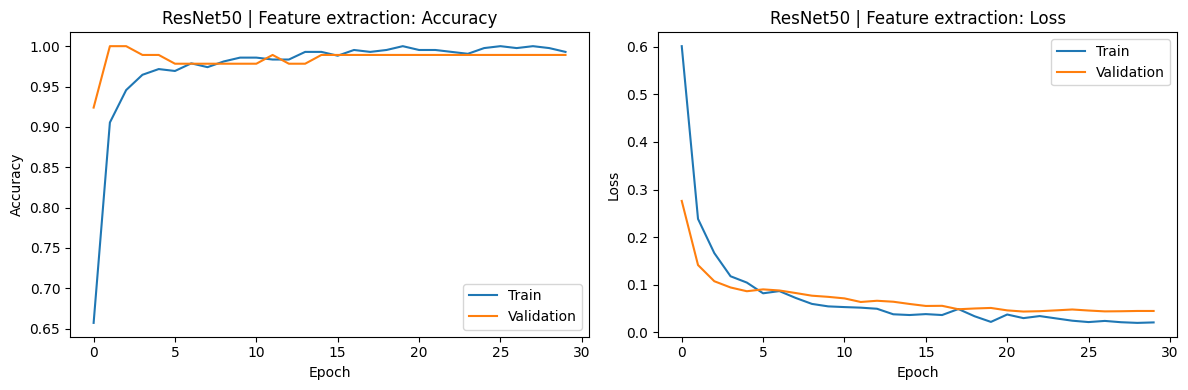

              precision    recall  f1-score   support

     Healthy     1.0000    1.0000    1.0000        33
     Scabies     1.0000    1.0000    1.0000        58

    accuracy                         1.0000        91
   macro avg     1.0000    1.0000    1.0000        91
weighted avg     1.0000    1.0000    1.0000        91



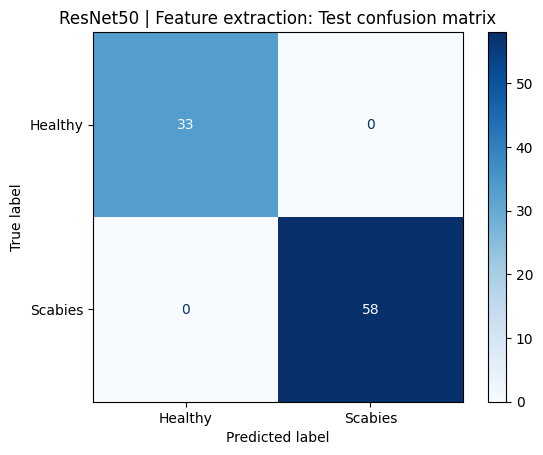

ResNet50 | Fine-tuning
Epoch 1/30
14/14 - 47s - 3s/step - accuracy: 0.6099 - loss: 0.7598 - val_accuracy: 0.7391 - val_loss: 0.5259 - learning_rate: 1.0000e-05
Epoch 2/30
14/14 - 7s - 527ms/step - accuracy: 0.8369 - loss: 0.4174 - val_accuracy: 0.8370 - val_loss: 0.3586 - learning_rate: 1.0000e-05
Epoch 3/30
14/14 - 8s - 545ms/step - accuracy: 0.9504 - loss: 0.2466 - val_accuracy: 0.8696 - val_loss: 0.2787 - learning_rate: 1.0000e-05
Epoch 4/30
14/14 - 8s - 536ms/step - accuracy: 0.9433 - loss: 0.1980 - val_accuracy: 0.8696 - val_loss: 0.2377 - learning_rate: 1.0000e-05
Epoch 5/30
14/14 - 10s - 736ms/step - accuracy: 0.9669 - loss: 0.1463 - val_accuracy: 0.8696 - val_loss: 0.2072 - learning_rate: 1.0000e-05
Epoch 6/30
14/14 - 10s - 736ms/step - accuracy: 0.9551 - loss: 0.1514 - val_accuracy: 0.9022 - val_loss: 0.1779 - learning_rate: 1.0000e-05
Epoch 7/30
14/14 - 8s - 544ms/step - accuracy: 0.9811 - loss: 0.1026 - val_accuracy: 0.9348 - val_loss: 0.1564 - learning_rate: 1.0000e-05
Epoc

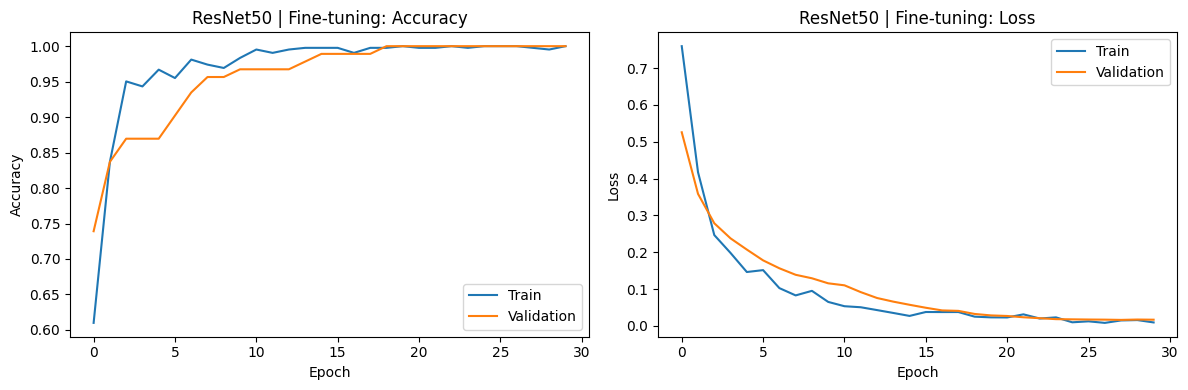

              precision    recall  f1-score   support

     Healthy     1.0000    1.0000    1.0000        33
     Scabies     1.0000    1.0000    1.0000        58

    accuracy                         1.0000        91
   macro avg     1.0000    1.0000    1.0000        91
weighted avg     1.0000    1.0000    1.0000        91



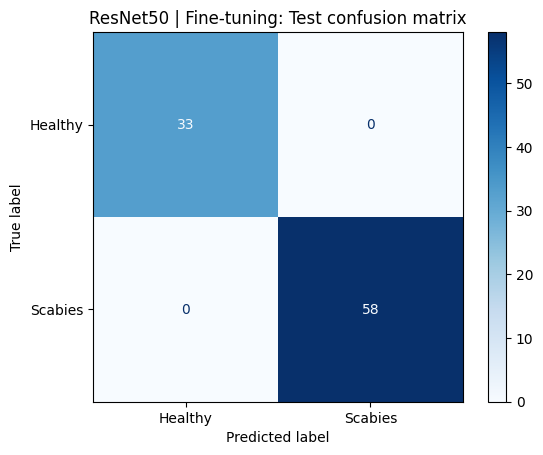

In [9]:
results = []
results.append(run('ResNet50', fine_tune=False))
results.append(run('ResNet50', fine_tune=True))

### 8.2 VGG16

VGG16 | Feature extraction
58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/30
14/14 - 18s - 1s/step - accuracy: 0.5343 - loss: 1.4189 - val_accuracy: 0.7174 - val_loss: 0.6754 - learning_rate: 0.0010
Epoch 2/30
14/14 - 2s - 175ms/step - accuracy: 0.7352 - loss: 0.7741 - val_accuracy: 0.8478 - val_loss: 0.3948 - learning_rate: 0.0010
Epoch 3/30
14/14 - 2s - 176ms/step - accuracy: 0.7896 - loss: 0.5405 - val_accuracy: 0.8804 - val_loss: 0.2520 - learning_rate: 0.0010
Epoch 4/30
14/14 - 2s - 175ms/step - accuracy: 0.8369 - loss: 0.4375 - val_accuracy: 0.9457 - val_loss: 0.1790 - learning_rate: 0.0010
Epoch 5/30
14/14 - 3s - 196ms/step - accuracy: 0.8723 - loss: 0.3532 - val_accuracy: 0.9674 - val_loss: 0.1363 - learning_rate: 0.0010
Epoch 6/30
14/14 - 2s - 175ms/step - accuracy: 0.8983 - loss: 0.2181 - val_accuracy: 0.9891 - val_loss: 0.1105 - learning_rate: 0.0010
Epoch 7/30
14/14 - 2s - 170ms/step - accuracy: 0.9007 - loss: 0.3007 - val_accuracy: 0.9891 - val_loss: 0.0958 - l

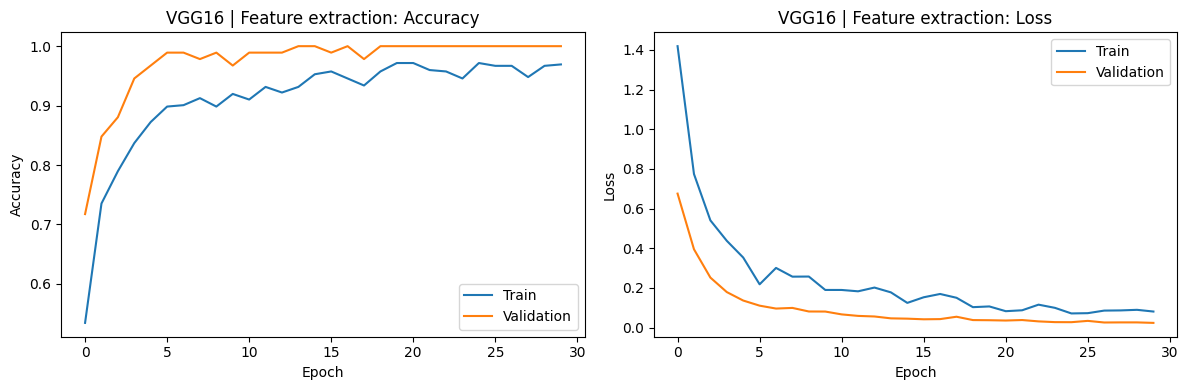

              precision    recall  f1-score   support

     Healthy     0.9706    1.0000    0.9851        33
     Scabies     1.0000    0.9828    0.9913        58

    accuracy                         0.9890        91
   macro avg     0.9853    0.9914    0.9882        91
weighted avg     0.9893    0.9890    0.9890        91



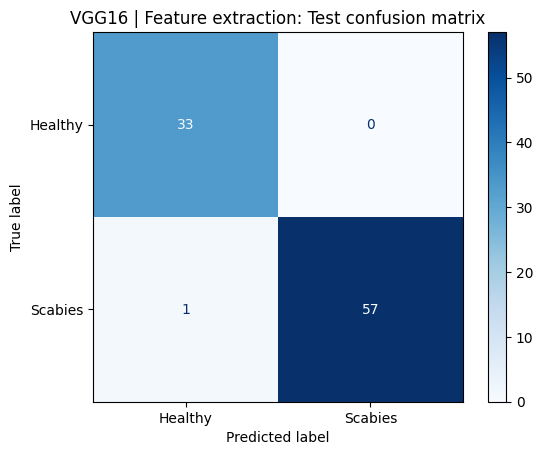

VGG16 | Fine-tuning
Epoch 1/30
14/14 - 32s - 2s/step - accuracy: 0.7234 - loss: 0.7089 - val_accuracy: 0.9239 - val_loss: 0.2252 - learning_rate: 1.0000e-05
Epoch 2/30
14/14 - 6s - 462ms/step - accuracy: 0.9480 - loss: 0.1350 - val_accuracy: 0.9783 - val_loss: 0.0784 - learning_rate: 1.0000e-05
Epoch 3/30
14/14 - 6s - 461ms/step - accuracy: 0.9645 - loss: 0.0790 - val_accuracy: 0.9891 - val_loss: 0.0491 - learning_rate: 1.0000e-05
Epoch 4/30
14/14 - 6s - 454ms/step - accuracy: 0.9835 - loss: 0.0481 - val_accuracy: 0.9783 - val_loss: 0.0474 - learning_rate: 1.0000e-05
Epoch 5/30
14/14 - 6s - 451ms/step - accuracy: 0.9905 - loss: 0.0295 - val_accuracy: 0.9674 - val_loss: 0.0885 - learning_rate: 1.0000e-05
Epoch 6/30
14/14 - 6s - 448ms/step - accuracy: 0.9929 - loss: 0.0283 - val_accuracy: 0.9783 - val_loss: 0.0538 - learning_rate: 1.0000e-05
Epoch 7/30
14/14 - 6s - 450ms/step - accuracy: 0.9858 - loss: 0.0210 - val_accuracy: 0.9783 - val_loss: 0.0704 - learning_rate: 1.0000e-05
Epoch 8/3

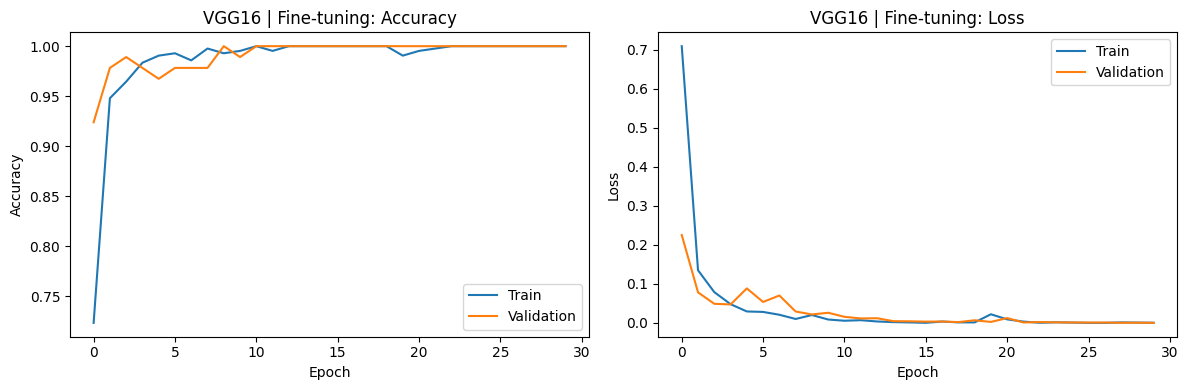

              precision    recall  f1-score   support

     Healthy     0.9706    1.0000    0.9851        33
     Scabies     1.0000    0.9828    0.9913        58

    accuracy                         0.9890        91
   macro avg     0.9853    0.9914    0.9882        91
weighted avg     0.9893    0.9890    0.9890        91



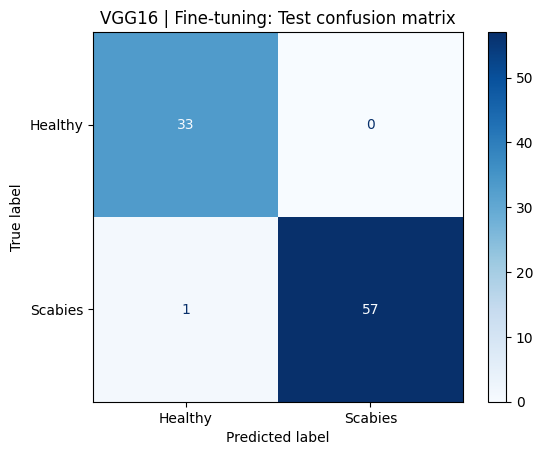

In [10]:
results.append(run('VGG16', fine_tune=False))
results.append(run('VGG16', fine_tune=True))

### 8.3 EfficientNetB0

EfficientNetB0 | Feature extraction
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/30
14/14 - 17s - 1s/step - accuracy: 0.6288 - loss: 0.6404 - val_accuracy: 0.8478 - val_loss: 0.5240 - learning_rate: 0.0010
Epoch 2/30
14/14 - 1s - 97ms/step - accuracy: 0.8983 - loss: 0.4127 - val_accuracy: 0.9565 - val_loss: 0.3667 - learning_rate: 0.0010
Epoch 3/30
14/14 - 1s - 100ms/step - accuracy: 0.9456 - loss: 0.3044 - val_accuracy: 0.9783 - val_loss: 0.2810 - learning_rate: 0.0010
Epoch 4/30
14/14 - 2s - 112ms/step - accuracy: 0.9504 - loss: 0.2471 - val_accuracy: 1.0000 - val_loss: 0.2286 - learning_rate: 0.0010
Epoch 5/30
14/14 - 2s - 109ms/step - accuracy: 0.9622 - loss: 0.1990 - val_accuracy: 1.0000 - val_loss: 0.1958 - learning_rate: 0.0010
Epoch 6/30
14/14 - 1s - 101ms/step - accuracy: 0.9693 - loss: 0.1853 - val_accuracy: 1.0000 - val_loss: 0.1708 - learning_rate: 0.0010
Epoch 7/30
14/14 - 1s - 99ms/step - accuracy: 0.9740 - loss: 0.1610 - val_accuracy: 1.0000 - val_loss: 0.1

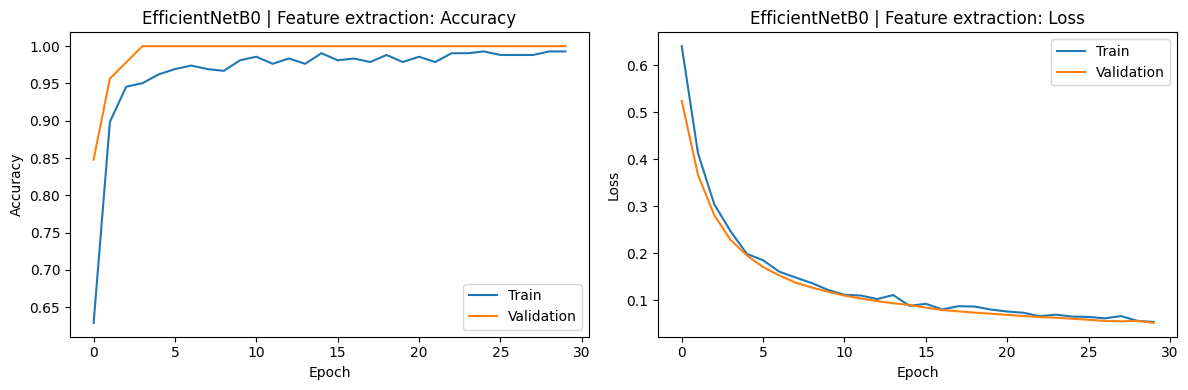

              precision    recall  f1-score   support

     Healthy     1.0000    1.0000    1.0000        33
     Scabies     1.0000    1.0000    1.0000        58

    accuracy                         1.0000        91
   macro avg     1.0000    1.0000    1.0000        91
weighted avg     1.0000    1.0000    1.0000        91



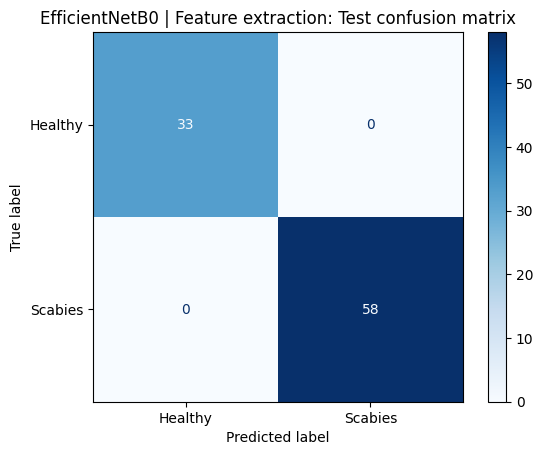

EfficientNetB0 | Fine-tuning
Epoch 1/30
14/14 - 43s - 3s/step - accuracy: 0.5674 - loss: 0.7249 - val_accuracy: 0.3804 - val_loss: 0.7697 - learning_rate: 1.0000e-05
Epoch 2/30
14/14 - 5s - 346ms/step - accuracy: 0.6785 - loss: 0.6439 - val_accuracy: 0.5109 - val_loss: 0.7186 - learning_rate: 1.0000e-05
Epoch 3/30
14/14 - 5s - 352ms/step - accuracy: 0.7163 - loss: 0.6025 - val_accuracy: 0.5761 - val_loss: 0.6728 - learning_rate: 1.0000e-05
Epoch 4/30
14/14 - 5s - 343ms/step - accuracy: 0.8038 - loss: 0.5423 - val_accuracy: 0.6304 - val_loss: 0.6323 - learning_rate: 1.0000e-05
Epoch 5/30
14/14 - 5s - 353ms/step - accuracy: 0.8274 - loss: 0.5204 - val_accuracy: 0.6848 - val_loss: 0.5947 - learning_rate: 1.0000e-05
Epoch 6/30
14/14 - 5s - 356ms/step - accuracy: 0.8865 - loss: 0.4695 - val_accuracy: 0.7283 - val_loss: 0.5608 - learning_rate: 1.0000e-05
Epoch 7/30
14/14 - 5s - 348ms/step - accuracy: 0.8794 - loss: 0.4437 - val_accuracy: 0.7609 - val_loss: 0.5311 - learning_rate: 1.0000e-05


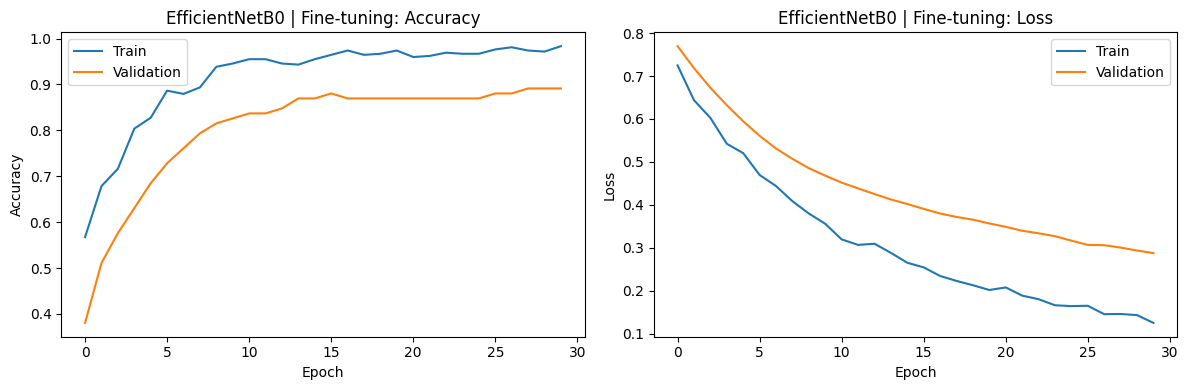

              precision    recall  f1-score   support

     Healthy     0.8049    1.0000    0.8919        33
     Scabies     1.0000    0.8621    0.9259        58

    accuracy                         0.9121        91
   macro avg     0.9024    0.9310    0.9089        91
weighted avg     0.9292    0.9121    0.9136        91



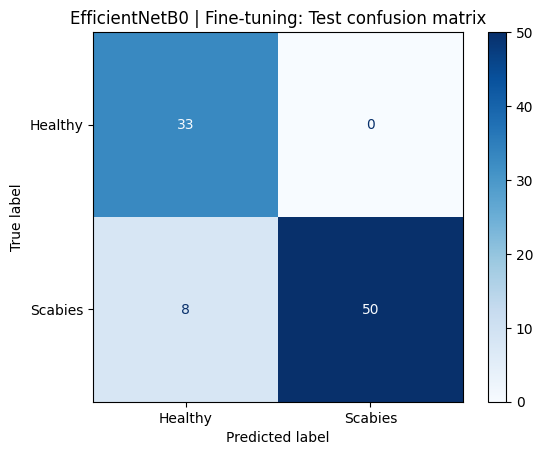

In [11]:
results.append(run('EfficientNetB0', fine_tune=False))
results.append(run('EfficientNetB0', fine_tune=True))

## 9. Results table
`Train-Val Gap` = final train accuracy minus final validation accuracy.
- Gap above about 0.10 with validation loss rising: **overfitting**.
- Both train and validation accuracy low: **underfitting**.

In [12]:
results_df = pd.DataFrame(results)
results_df

,Model,Mode,Train Acc,Val Acc,Test Acc,Precision,Recall,F1,Train-Val Gap,Time (min)
0,ResNet50,Feature extraction,0.9929,0.9891,1.0000,1.0000,1.0000,1.0000,0.0038,1.5
1,ResNet50,Fine-tuning,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0.0000,4.6
2,VGG16,Feature extraction,0.9693,1.0000,0.9890,0.9853,0.9914,0.9882,-0.0307,1.5
3,VGG16,Fine-tuning,1.0000,1.0000,0.9890,0.9853,0.9914,0.9882,0.0000,3.6
4,EfficientNetB0,Feature extraction,0.9929,1.0000,1.0000,1.0000,1.0000,1.0000,-0.0071,1.0
5,EfficientNetB0,Fine-tuning,0.9835,0.8913,0.9121,0.9024,0.9310,0.9089,0.0921,3.1


## 10. Fix overfitting or underfitting
Look at the curves above and the table, find the worst run, then re-run it with a fix.

**Overfitting** (train accuracy high, validation loss rising): more dropout, unfreeze fewer layers, lower learning rate.
**Underfitting** (both accuracies low): unfreeze more layers, higher learning rate, no extra dropout.

Edit the example below to match the problem you found. Write one markdown line saying what you saw and what you changed, and keep the before and after curves.

ResNet50 | Fine-tuning (fixed)
Epoch 1/30
14/14 - 17s - 1s/step - accuracy: 0.6288 - loss: 0.6571 - val_accuracy: 0.7283 - val_loss: 0.5950 - learning_rate: 1.0000e-05
Epoch 2/30
14/14 - 3s - 230ms/step - accuracy: 0.8085 - loss: 0.4161 - val_accuracy: 0.8370 - val_loss: 0.4121 - learning_rate: 1.0000e-05
Epoch 3/30
14/14 - 3s - 217ms/step - accuracy: 0.8771 - loss: 0.2944 - val_accuracy: 0.8696 - val_loss: 0.3076 - learning_rate: 1.0000e-05
Epoch 4/30
14/14 - 3s - 218ms/step - accuracy: 0.8960 - loss: 0.2424 - val_accuracy: 0.9022 - val_loss: 0.2437 - learning_rate: 1.0000e-05
Epoch 5/30
14/14 - 3s - 215ms/step - accuracy: 0.9314 - loss: 0.1875 - val_accuracy: 0.9239 - val_loss: 0.1992 - learning_rate: 1.0000e-05
Epoch 6/30
14/14 - 3s - 216ms/step - accuracy: 0.9314 - loss: 0.1683 - val_accuracy: 0.9457 - val_loss: 0.1629 - learning_rate: 1.0000e-05
Epoch 7/30
14/14 - 3s - 217ms/step - accuracy: 0.9456 - loss: 0.1453 - val_accuracy: 0.9565 - val_loss: 0.1391 - learning_rate: 1.0000e-0

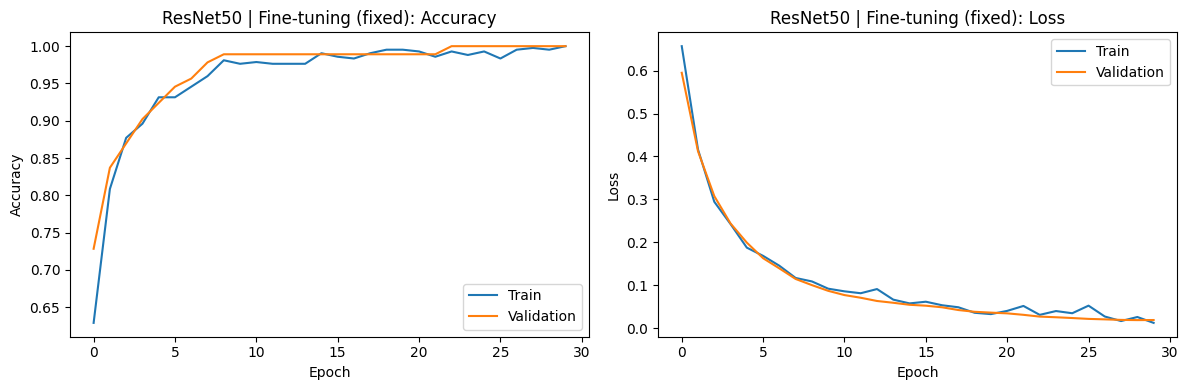

              precision    recall  f1-score   support

     Healthy     1.0000    1.0000    1.0000        33
     Scabies     1.0000    1.0000    1.0000        58

    accuracy                         1.0000        91
   macro avg     1.0000    1.0000    1.0000        91
weighted avg     1.0000    1.0000    1.0000        91



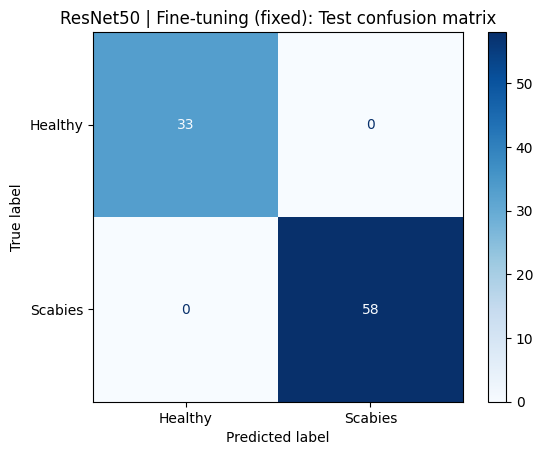

,Model,Mode,Train Acc,Val Acc,Test Acc,Precision,Recall,F1,Train-Val Gap,Time (min)
0,ResNet50,Feature extraction,0.9929,0.9891,1.0000,1.0000,1.0000,1.0000,0.0038,1.5
1,ResNet50,Fine-tuning,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0.0000,4.6
2,VGG16,Feature extraction,0.9693,1.0000,0.9890,0.9853,0.9914,0.9882,-0.0307,1.5
3,VGG16,Fine-tuning,1.0000,1.0000,0.9890,0.9853,0.9914,0.9882,0.0000,3.6
4,EfficientNetB0,Feature extraction,0.9929,1.0000,1.0000,1.0000,1.0000,1.0000,-0.0071,1.0
5,EfficientNetB0,Fine-tuning,0.9835,0.8913,0.9121,0.9024,0.9310,0.9089,0.0921,3.1
6,ResNet50,Fine-tuning (fixed),1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0.0000,1.8


In [13]:
fix_result = run('ResNet50', fine_tune=True, dropout=0.5, last_layers=30, lr=1e-5, tag=' (fixed)')
results.append(fix_result)
pd.DataFrame(results)

## 11. Conclusion
Write 3 to 4 sentences here: which model and mode gave the best test F1, whether fine-tuning helped, what overfitting or underfitting you found, and what you changed to fix it.